In [1]:
import sys

sys.path.append("..")

import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns

from analysis.utils import get_runs_data, show_config_differences

sns.set_style(style="darkgrid")

In [2]:
metric = "train/exact_match_embed_cond"

data_7m = get_runs_data(tag="final-conditions-7M", project="memorization", metrics=[metric])
data_14m = get_runs_data(tag="final-conditions-14M", project="memorization", metrics=[metric])

# Filter to conditions.yaml runs
for name, df in [("data_7m", data_7m), ("data_14m", data_14m)]:
    mask = (df["cfg.dataset_metadata.vocab_size"] == 100) & (df["cfg.dataset_metadata.num_samples"] == 6000)
    if name == "data_7m":
        data_7m = df[mask].copy()
    else:
        data_14m = df[mask].copy()

print(f"After filtering: {data_7m['_run_id'].nunique()} runs (7M), {data_14m['_run_id'].nunique()} runs (14M)")

Found 32 runs with tag 'final-conditions-7M'
Found 20 runs with tag 'final-conditions-14M'
After filtering: 24 runs (7M), 20 runs (14M)


In [3]:
for label, df in [("7M", data_7m), ("14M", data_14m)]:
    runs = df.groupby("_run_id").first()
    runs["cfg.dataset_metadata.target_level"] = runs["cfg.dataset_metadata.target_level"].astype(str)
    seeds = sorted(runs["cfg.dataset_metadata.seed"].unique())
    print(f"=== {label} === ({len(runs)} runs, seeds: {seeds})")
    counts = runs.groupby(["cfg.dataset_metadata.target_level", "cfg.dataset_metadata.strategy"]).size().rename("n_seeds")
    print(counts.to_string())
    print()

=== 7M === (24 runs, seeds: [np.int64(0), np.int64(1), np.int64(2)])
cfg.dataset_metadata.target_level  cfg.dataset_metadata.strategy
2a                                 lookback                         3
                                   modulo                           3
                                   polynomial_prime                 3
                                   random                           3
                                   sin                              3

=== 14M === (20 runs, seeds: [np.int64(0), np.int64(1), np.int64(2)])
cfg.dataset_metadata.target_level  cfg.dataset_metadata.strategy
2a                                 lookback                         3
                                   modulo                           3
                                   polynomial_prime                 2
                                   random                           3
                                   sin                              3



In [13]:
def plot_level_curves(data, metric, title, save_path=None):
    level_col = "cfg.dataset_metadata.target_level"
    step_col = "train/global_step"

    data[level_col] = data[level_col].astype(str)
    stats = data.groupby([level_col, step_col])[metric].agg(["mean", "std"]).reset_index()

    level_order = ["0", "1", "2a"]
    colors = sns.color_palette("husl", len(level_order))

    fig, ax = plt.subplots(figsize=(10, 6))
    for i, level in enumerate(level_order):
        level_data = stats[stats[level_col] == level].sort_values(step_col)
        if level_data.empty:
            continue
        steps = level_data[step_col]
        mean = level_data["mean"]
        std = level_data["std"].fillna(0)

        ax.plot(steps, mean, label=f"{level}", color=colors[i], linewidth=2)
        ax.fill_between(steps, np.clip(mean - std, 0, 1), np.clip(mean + std, 0, 1), alpha=0.2, color=colors[i])

    ax.set_xlabel("Training Step", fontsize=20)
    ax.set_ylabel("Exact Match (Mean \u00b1 Std)", fontsize=20)
    ax.tick_params(axis="both", labelsize=16)
    ax.legend(title="Level", fontsize=16, title_fontsize=18)
    # ax.set_title(title, fontsize=22)
    plt.tight_layout()
    if save_path:
        fig.savefig(save_path, bbox_inches="tight")
    plt.show()

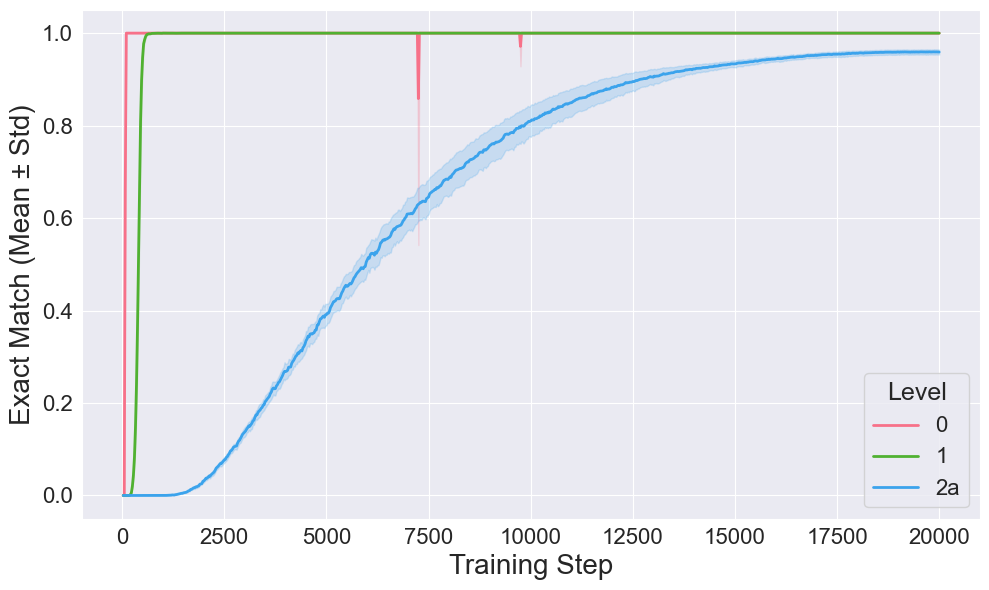

In [14]:
plot_level_curves(data_7m, metric, "Exact Match by Level - 7M", save_path="conditions_7m.pdf")

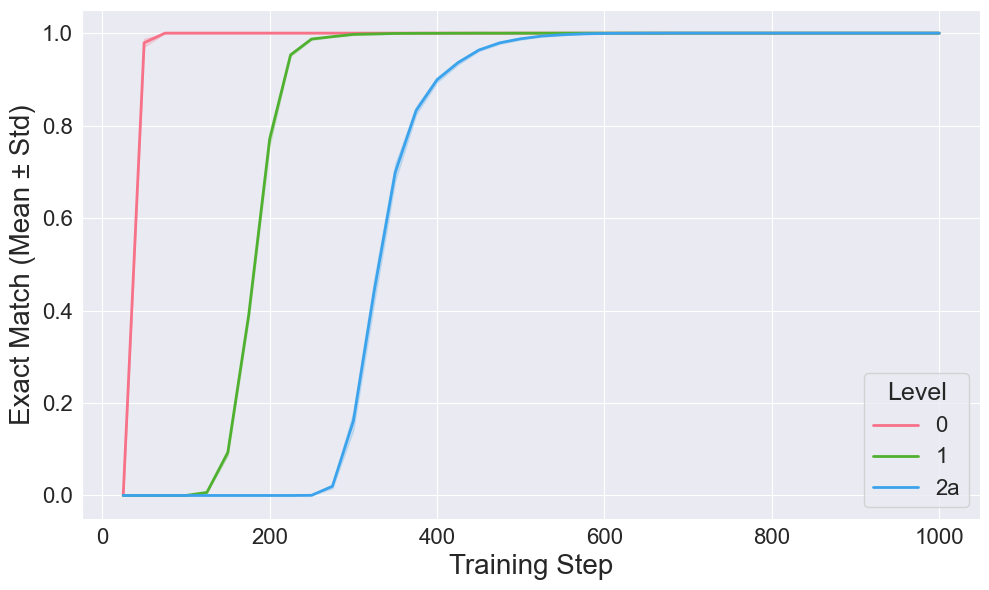

In [15]:
plot_level_curves(data_14m, metric, "Exact Match by Level - 14M", save_path="conditions_14m.pdf")